# Fast Agent - Build a SQL Agent fast!

<img src="./assets/LC_L1_top.png" align="left" width="500">

## Setup

Load and/or check for needed environmental variables

In [1]:
from dotenv import load_dotenv
from env_utils import doublecheck_env, doublecheck_pkgs

# Load environment variables from .env
load_dotenv()

# Check and print results
doublecheck_env("example.env")  # check environmental variables
doublecheck_pkgs(pyproject_path="pyproject.toml", verbose=True)   # check packages

OPENAI_API_KEY=<not set>
LANGSMITH_API_KEY=****954e
LANGSMITH_TRACING=true
LANGSMITH_PROJECT=****ials
Python 3.13.9 satisfies requires-python: >=3.11,<3.14
package                | required | installed | status | path                                                   
---------------------- | -------- | --------- | ------ | -------------------------------------------------------
langgraph              | >=1.0.0  | 1.0.5     | ✅ OK   | f:\Cursos_code\langchain_course\.venv\Lib\site-packages
langchain              | >=1.0.0  | 1.2.0     | ✅ OK   | f:\Cursos_code\langchain_course\.venv\Lib\site-packages
langchain-core         | >=1.0.0  | 1.2.2     | ✅ OK   | f:\Cursos_code\langchain_course\.venv\Lib\site-packages
langchain-openai       | >=1.0.0  | 1.1.4     | ✅ OK   | f:\Cursos_code\langchain_course\.venv\Lib\site-packages
langchain-aws          | (any)    | 1.1.0     | ✅ OK   | f:\Cursos_code\langchain_course\.venv\Lib\site-packages
boto3                  | (any)    | 1.42.11   | ✅ OK 

In [2]:
from langchain_community.utilities import SQLDatabase

db = SQLDatabase.from_uri("sqlite:///Chinook.db")

Define the runtime context to provide the agent and tools with access to the database.

In [3]:
from dataclasses import dataclass

from langchain_community.utilities import SQLDatabase


# define context structure to support dependency injection
@dataclass
class RuntimeContext:
    db: SQLDatabase

<b>⚠️ Security Note:</b> This demo does not include a filter on LLM-generated commands. In production, you would want to limit the scope of LLM-generated commands. ⚠️   
This tool will connect to the database. Note the use of `get_runtime` to access the graph **runtime context**.

In [4]:
from langchain_core.tools import tool
from langgraph.runtime import get_runtime

@tool
def execute_sql(query: str) -> str:
    """Execute a SQLite command and return results."""
    runtime = get_runtime(RuntimeContext)
    db = runtime.context.db

    try:
        return db.run(query)
    except Exception as e:
        return f"Error: {e}"

Add a system prompt to define your agents behavior.

In [5]:
SYSTEM_PROMPT = """You are a careful SQLite analyst.

Rules:
- Think step-by-step.
- When you need data, call the tool `execute_sql` with ONE SELECT query.
- Read-only only; no INSERT/UPDATE/DELETE/ALTER/DROP/CREATE/REPLACE/TRUNCATE.
- Limit to 5 rows of output unless the user explicitly asks otherwise.
- If the tool returns 'Error:', revise the SQL and try again.
- Prefer explicit column lists; avoid SELECT *.
"""

Create your agent! Add a model, tools, a prompt, and the runtime access, and go!  You can choose many agents from our [integrations](https://docs.langchain.com/oss/python/integrations/providers) list. 

In [10]:
import os
import boto3
from botocore.config import Config
from langchain_aws import ChatBedrock
from langchain.agents import create_agent

# Configure retries to handle throttling
retry_config = Config(
    region_name="us-east-1",
    retries={
        'max_attempts': 10,
        'mode': 'standard'
    }
)

llm = ChatBedrock(
    model_id="amazon.nova-lite-v1:0",
    model_kwargs=dict(temperature=0),
    region_name=os.getenv("AWS_DEFAULT_REGION", "us-east-1"),
    config=retry_config
)

agent = create_agent(
    model=llm,
    tools=[execute_sql],
    system_prompt=SYSTEM_PROMPT,
    context_schema=RuntimeContext,
)

Here's a display of the agent ReAct Loop.

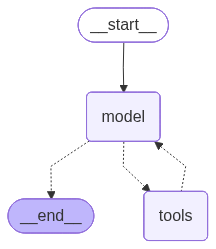

In [8]:
from IPython.display import Image, display

display(Image(agent.get_graph(xray=True).draw_mermaid_png()))

Run some queries. Notice:
- The agent does not have the database schema and will need to discover it independently.
- The agent may make mistakes! By returning error messages, the agent can self-correct its queries.
- Notice you invoke the agent with `agent.stream`.
    - This command and the `pretty_print` display the **messages** that communicate information between the model and the tools.
- Notice the agent doesn't remember the schema between invocations... More on this later!

In [11]:
question = "Which table has the largest number of entries?"

for step in agent.stream(
    {"messages": question},
    context=RuntimeContext(db=db),
    stream_mode="values",
):
    step["messages"][-1].pretty_print()

================================ Human Message =================================

Which table has the largest number of entries?
================================== Ai Message ==================================

[{'type': 'text', 'text': "<thinking> To determine which table has the largest number of entries, I need to execute a query to count the number of rows in each table. However, since I don't know the names of the tables in the database, I need to first fetch the list of tables.</thinking>\n"}, {'type': 'tool_use', 'name': 'execute_sql', 'input': {'query': "SELECT name FROM sqlite_master WHERE type='table';"}, 'id': 'tooluse_EjWk2195QtGRHfaQ4tNJ9A'}]
Tool Calls:
  execute_sql (tooluse_EjWk2195QtGRHfaQ4tNJ9A)
 Call ID: tooluse_EjWk2195QtGRHfaQ4tNJ9A
  Args:
    query: SELECT name FROM sqlite_master WHERE type='table';
================================= Tool Message =================================
Name: execute_sql

[('Album',), ('Artist',), ('Customer',), ('Employee',), ('Genre',)

In [12]:
question = "Which genre on average has the longest tracks?"

for step in agent.stream(
    {"messages": question},
    context=RuntimeContext(db=db),
    stream_mode="values",
):
    step["messages"][-1].pretty_print()

================================ Human Message =================================

Which genre on average has the longest tracks?
================================== Ai Message ==================================

[{'type': 'text', 'text': '<thinking> To determine which genre has the longest tracks on average, I need to query the database for the average duration of tracks for each genre. This will require joining the `tracks` table with the `genres` table and grouping by genre. </thinking>\n'}, {'type': 'tool_use', 'name': 'execute_sql', 'input': {'query': 'SELECT g.name AS genre, AVG(t.milliseconds) / 1000.0 AS avg_duration_seconds FROM tracks t JOIN genres g ON t.genre_id = g.id GROUP BY g.name;'}, 'id': 'tooluse_F7kMeVp1Sge7De3M6e65eA'}]
Tool Calls:
  execute_sql (tooluse_F7kMeVp1Sge7De3M6e65eA)
 Call ID: tooluse_F7kMeVp1Sge7De3M6e65eA
  Args:
    query: SELECT g.name AS genre, AVG(t.milliseconds) / 1000.0 AS avg_duration_seconds FROM tracks t JOIN genres g ON t.genre_id = g.id GROUP 

In [13]:
question = "Please list all of the tables"

for step in agent.stream(
    {"messages": question},
    context={"db": db},
    stream_mode="values",
):
    step["messages"][-1].pretty_print()

================================ Human Message =================================

Please list all of the tables
================================== Ai Message ==================================

[{'type': 'text', 'text': '<thinking>The task is to list all of the tables in the SQLite database. I should use the `execute_sql` tool with an appropriate SQL query to retrieve this information.</thinking>\n'}, {'type': 'tool_use', 'name': 'execute_sql', 'input': {'query': "SELECT name FROM sqlite_master WHERE type='table';"}, 'id': 'tooluse_Mcnj5ViGTHW5cN8Lx6PGtQ'}]
Tool Calls:
  execute_sql (tooluse_Mcnj5ViGTHW5cN8Lx6PGtQ)
 Call ID: tooluse_Mcnj5ViGTHW5cN8Lx6PGtQ
  Args:
    query: SELECT name FROM sqlite_master WHERE type='table';
================================= Tool Message =================================
Name: execute_sql

[('Album',), ('Artist',), ('Customer',), ('Employee',), ('Genre',), ('Invoice',), ('InvoiceLine',), ('MediaType',), ('Playlist',), ('PlaylistTrack',), ('Track',)]
===

**Create your own query here!**  Add some questions of your own.

In [ ]:
question = "TRY YOUR OWN QUERY HERE"

for step in agent.stream(
    {"messages": question},
    context={"db": db},
    stream_mode="values",
):
    step["messages"][-1].pretty_print()

================================ Human Message =================================

TRY YOUR OWN QUERY HERE
================================== Ai Message ==================================

[{'type': 'text', 'text': '<thinking>Given that there is no specific query from the user, I will start by listing the available tables in the database. This will provide a foundation for further analysis and understanding of the database structure.</thinking>\n'}, {'type': 'tool_use', 'name': 'execute_sql', 'input': {'query': "SELECT name FROM sqlite_master WHERE type='table';"}, 'id': 'tooluse_qc0rGLQUTsm1vg6fTBtSQw'}]
Tool Calls:
  execute_sql (tooluse_qc0rGLQUTsm1vg6fTBtSQw)
 Call ID: tooluse_qc0rGLQUTsm1vg6fTBtSQw
  Args:
    query: SELECT name FROM sqlite_master WHERE type='table';
================================= Tool Message =================================
Name: execute_sql

[('Album',), ('Artist',), ('Customer',), ('Employee',), ('Genre',), ('Invoice',), ('InvoiceLine',), ('MediaType',), ('

: 

### Let's try this Studio